# BioGuard-X | Task 2 — Complete Research & Deployment Notebook
### Hierarchical Multimodal Biometric Verification (TRADITIONAL ML ONLY)

**Real data:** RAVDESS full audiovisual *speech* MP4 archives `Video_Speech_Actor_01.zip` → `Video_Speech_Actor_07.zip` stored in **Windows Downloads** (or `raw_ravdess/`). No full 25 GB download. **No Deep Learning, TensorFlow, pretrained face embeddings, or fake performance claims.**

This notebook shows: **1. Dataset exploration → 2. Preprocessing → 3. HOG & LBP (image) → 4. MFCC, Δ, ΔΔ, ZCR, RMS (audio) → 5. Video temporal features → 6. Pairwise verification model training (SVM/RF) → 7. Metrics, confusion matrices, ROC/FAR/FRR → 8. Early fusion → 9. Late fusion → 10. Hierarchical verification → 11. Open-set unknown rejection → 12. Model comparison → 13. Export for Flask → 14. Bonuses: commands, webcam/microphone, team enrollment, fingerprint.**

**How to run:** follow `README_AR.md` and `setup_venv.ps1`; select kernel **Python (BioGuard Task 2)**; then **Run All** (the first data-processing run can be lengthy). Files exported to **`model/`**, plots to **`outputs/`**.

**Scientific caution:** The dataset trains a *same-person vs different-person verifier* conditioned on a gallery template; `Actor 01…05` are enrolled known identities in this experiment; actor 06 is *unknown validation*, actor 07 is *unknown test*. A fresh employee can enroll via a NEW local gallery later. The verifier may perform worse on different cameras, lighting, accents, or languages. Testing unseen people and attack resistance is mandatory before any real access control.

Dataset: [RAVDESS — Zenodo DOI:10.5281/zenodo.1188976](https://zenodo.org/records/1188976); CC BY-NC-SA 4.0.

## 0. Requirements / Virtual Environment / Reproducibility
The versions are displayed to verify Jupyter is running in your new `.venv`. Using `joblib` files from unknown sources is unsafe: **load only your own trusted export.**

In [1]:
import sys, os, platform, inspect, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, librosa, sklearn, skimage, scipy, soundfile, joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import bioguard_core as core
import prepare_ravdess as prep
import public_research as research
import deployment

plt.rcParams.update({'figure.figsize':(10,5),'font.size':10})
SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd()
DATA_DIR = ROOT/'public_data'
MODEL_DIR = ROOT/'model'
OUT_DIR = ROOT/'outputs'
for directory in [DATA_DIR, MODEL_DIR, OUT_DIR]: directory.mkdir(parents=True,exist_ok=True)
print('Python:',sys.version.split()[0], '\nExecutable:',sys.executable)
print('Library versions:', {x:mod.__version__ for x,mod in [('numpy',np),('pandas',pd),('opencv',cv2),('librosa',librosa),('scikit-learn',sklearn)]})
print('Project:',ROOT.resolve())
assert sys.version_info >= (3,10), 'Use Python 3.12 recommended'

Python: 3.11.9 
Executable: c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Scripts\python.exe
Library versions: {'numpy': '2.4.6', 'pandas': '3.1.1', 'opencv': '4.14.0', 'librosa': '0.11.0', 'scikit-learn': '1.9.1'}
Project: <PROJECT_ROOT>\Downloads\BioGuard_Task2_COMPLETE


## 1. Input ZIP Audit — seven actors, zero extra downloads
We inspect ZIPs from `~/Downloads` directly. **Each `01-01-...mp4` file contains BOTH video and its own aligned speech audio.** We ignore `02-01-...mp4` video-only duplicates and do **not** download the songs or separate audio archive. Actor IDs are identities; **emotion labels are NOT target identities**.

In [4]:
ZIP_SOURCE = None   # If needed set: r'D:\RAVDESS-ZIPS' ; default searches Downloads
archives = prep.locate_archives(ZIP_SOURCE)  # Searches Downloads + raw_ravdess/
audit=[]
import zipfile
for actor, path in archives.items():
    with zipfile.ZipFile(path) as z:
        full_av=[f for f in z.namelist() if prep.PATTERN.match(Path(f).name)
                 and int(prep.PATTERN.match(Path(f).name).group(7))==actor]
    audit.append({'actor':actor,'archive':path.name,'zip_size_MB':round(path.stat().st_size/1e6,1),
                  'full_AV_speech_clips':len(full_av),'role':'known' if actor<=5 else 'val_unknown' if actor==6 else 'test_unknown'})
zip_audit=pd.DataFrame(audit)
display(zip_audit)
assert len(zip_audit)==7 and (zip_audit.full_AV_speech_clips>0).all(), 'Missing/incorrect ZIP archives'

,actor,archive,zip_size_MB,full_AV_speech_clips,role
0,1,Video_Speech_Actor_01.zip,553.0,60,known
1,2,Video_Speech_Actor_02.zip,570.7,60,known
2,3,Video_Speech_Actor_03.zip,567.8,60,known
3,4,Video_Speech_Actor_04.zip,546.6,60,known
4,5,Video_Speech_Actor_05.zip,563.0,60,known
5,6,Video_Speech_Actor_06.zip,568.5,60,val_unknown
6,7,Video_Speech_Actor_07.zip,565.7,60,test_unknown


## 2. Dataset Preparation — matched image + audio + video
Extract a **small but useful balanced subset** (`MAX_CLIPS_PER_ACTOR=28`; approximately 196 source MP4 clips), NOT every file. For each original clip, save ONE frontal still `.png`, ONE WAV extracted from the same MP4 `.wav`, and the remaining 5–6 face frames in `.npz`. Repeatably split known people by **emotion+statement group** before processing to reduce near-duplicate leakage between splits. Unknown actor 06 is used only for threshold calibration, actor 07 is untouched until testing. For a stronger study increase to 40–50 clips/actor once everything works.

In [5]:
MAX_CLIPS_PER_ACTOR = 28  # change to 40 after successful first Run All
start = time.perf_counter()
manifest = prep.prepare(source=ZIP_SOURCE,max_clips=MAX_CLIPS_PER_ACTOR)
print(f'Prepared {len(manifest)} aligned triplets in {(time.perf_counter()-start)/60:.1f} minutes')
assert {'enroll','train','val','test','val_unknown','test_unknown'} <= set(manifest.split)

Actor 01 — Video_Speech_Actor_01.zip
  8/27 processed
  16/27 processed
  24/27 processed
Actor 02 — Video_Speech_Actor_02.zip
  8/27 processed
  16/27 processed
  24/27 processed
Actor 03 — Video_Speech_Actor_03.zip
  8/27 processed
  16/27 processed
  24/27 processed
Actor 04 — Video_Speech_Actor_04.zip
  8/27 processed
  16/27 processed
  24/27 processed
Actor 05 — Video_Speech_Actor_05.zip
  8/27 processed
  16/27 processed
  24/27 processed
Actor 06 — Video_Speech_Actor_06.zip
  8/28 processed
  16/28 processed
  24/28 processed
Actor 07 — Video_Speech_Actor_07.zip
  8/28 processed
  16/28 processed
  24/28 processed

Prepared 191 real matched audio/image/video clips
user      split       
actor_01  enroll           6
          test             5
          train           11
          val              5
actor_02  enroll           6
          test             5
          train           11
          val              5
actor_03  enroll           6
          test             5
      

## 3. Dataset Exploration (EDA): identities, splits, label balance, emotion
**RAVDESS is an emotional expression dataset** reused here as a biometric verification benchmark. All image/voice/video records must share the SAME sample identifier and actor. Every output below is computed from your files, never hardcoded accuracy.

,user,actor,split,sample,image,voice,video,emotion,statement,repetition
0,actor_01,1,train,01-01-04-02-01-02-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,4,1,2
1,actor_01,1,enroll,01-01-05-01-02-02-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,5,2,2
2,actor_01,1,train,01-01-08-01-02-02-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,8,2,2
3,actor_01,1,train,01-01-06-02-01-01-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,6,1,1
4,actor_01,1,enroll,01-01-05-02-02-02-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,5,2,2
5,actor_01,1,train,01-01-02-02-02-01-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,2,2,1
6,actor_01,1,enroll,01-01-07-02-02-01-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,7,2,1
7,actor_01,1,val,01-01-04-02-02-01-01,\Downloads\BioGuar...,\Downloads\BioGuar...,\Downloads\BioGuar...,4,2,1


split,enroll,test,test_unknown,train,val,val_unknown
user,,,,,,
actor_01,6,5,0,11,5,0
actor_02,6,5,0,11,5,0
actor_03,6,5,0,11,5,0
actor_04,6,5,0,11,5,0
actor_05,6,5,0,11,5,0
actor_06,0,0,0,0,0,28
actor_07,0,0,28,0,0,0


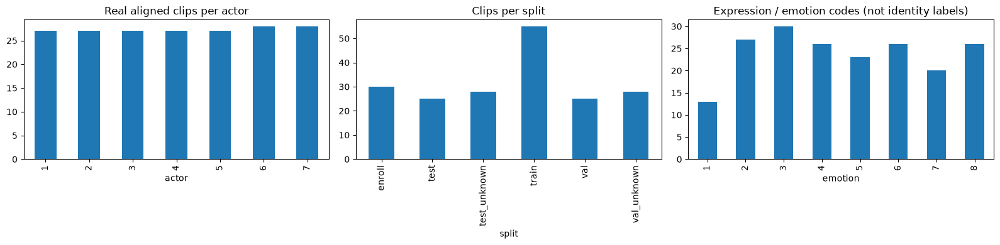

Leakage audit OK: actor 06 only validation unknown; actor 07 only test unknown.


In [6]:
display(manifest.head(8))
display(pd.crosstab(manifest.user,manifest.split).fillna(0))
fig,axs=plt.subplots(1,3,figsize=(16,4))
manifest.groupby('actor').size().plot.bar(ax=axs[0],title='Real aligned clips per actor')
manifest.groupby('split').size().plot.bar(ax=axs[1],title='Clips per split')
manifest.groupby('emotion').size().plot.bar(ax=axs[2],title='Expression / emotion codes (not identity labels)')
plt.tight_layout(); plt.savefig(OUT_DIR/'01_dataset_exploration.png',dpi=150);plt.show()
assert not manifest[['user','sample']].duplicated().any(), 'Duplicate clip IDs -> leakage'
assert set(manifest[manifest.split=='val_unknown'].actor)=={6}
assert set(manifest[manifest.split=='test_unknown'].actor)=={7}
assert set(manifest[manifest.split.isin(['enroll','train','val','test'])].actor)==set(range(1,6))
print('Leakage audit OK: actor 06 only validation unknown; actor 07 only test unknown.')

## 4. Show the aligned triple — face image, video frames, voice waveform
The video is a set of multiple **face observations over time**, not a new biometric organ. Face+Video comparisons are therefore highly correlated; **Face+Voice** is the meaningful two-biometric requirement.

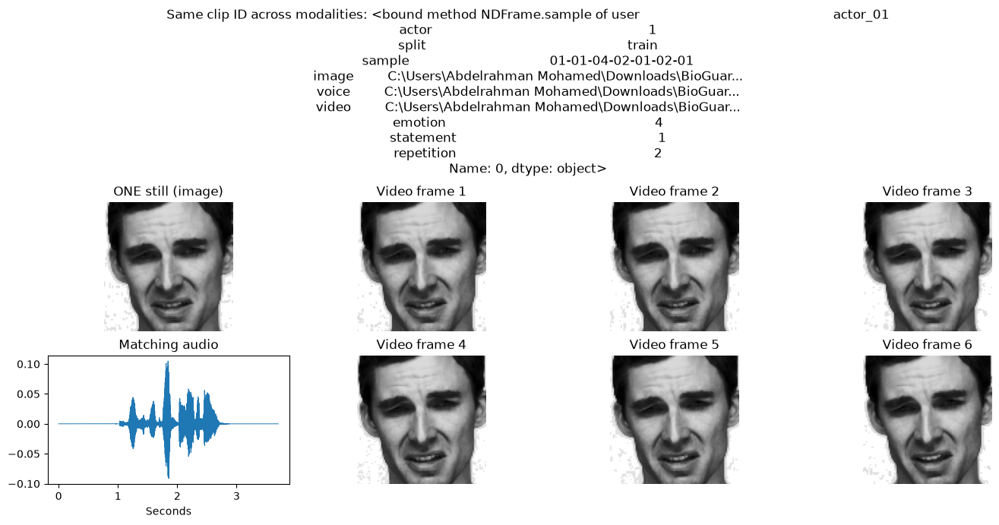

In [7]:
example=manifest.iloc[0]
still=cv2.imread(example.image,cv2.IMREAD_GRAYSCALE)
with np.load(example.video) as v: vf=v['frames']
y,sr=librosa.load(example.voice,sr=16000)
fig,ax=plt.subplots(2,4,figsize=(14,7))
ax[0,0].imshow(still,cmap='gray');ax[0,0].set_title('ONE still (image)')
for i in range(1,4): ax[0,i].imshow(vf[i-1],cmap='gray');ax[0,i].set_title(f'Video frame {i}')
ax[1,0].plot(np.arange(len(y))/sr,y,lw=.7);ax[1,0].set_title('Matching audio');ax[1,0].set_xlabel('Seconds')
for i in range(1,4):
    j=i+2
    if j<len(vf):
        ax[1,i].imshow(vf[j],cmap='gray');ax[1,i].set_title(f'Video frame {j+1}')
    else:
        ax[1,i].axis('off')
for a in ax.flat:a.axis('off') if a!=ax[1,0] else None
plt.suptitle(f'Same clip ID across modalities: {example.sample}')
plt.tight_layout();plt.savefig(OUT_DIR/'02_aligned_triplet.png',dpi=150);plt.show()

## 5. Preprocessing — exact steps and why
**Image/Video:** OpenCV classical Haar face detection → tight crop → resize to 96×96 → grayscale → histogram equalization. **Audio:** mono 16 kHz → trim silence → pad/crop to 3 s → short overlapping frames. **No training statistics (e.g. StandardScaler) are fitted on val/test:** scaling lives inside the sklearn Pipeline, so `fit()` sees train only. The prep script saves *already cropped* images; the runtime processes RAW webcam input with face detection first.

In [8]:
print('Image preprocessing and HOG/LBP extractor:')
print(inspect.getsource(core.extract_face))
print('Audio preprocessing and feature extraction:')
print(inspect.getsource(core.extract_voice))
print('AV extraction / face crop:')
print(inspect.getsource(prep.extract_frames))

Image preprocessing and HOG/LBP extractor:
def extract_face(image_or_path, require_face=True, already_cropped=False):
    """Face crop with classic Haar detector; HOG + LBP, grayscale 96x96.
    already_cropped=True for public images ALREADY cropped during ZIP preparation.
    """
    image = cv2.imread(str(image_or_path)) if isinstance(image_or_path, (str, Path)) else image_or_path
    gray = _gray(image)
    cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    detector = cv2.CascadeClassifier(cascade_path)
    if detector.empty():
        raise RuntimeError("OpenCV Haar cascade is missing")
    faces = [] if already_cropped else detector.detectMultiScale(gray, 1.1, 4, minSize=(35, 35))
    if len(faces) == 0:
        if require_face and not already_cropped:
            raise ValueError("No frontal face detected: capture again with good lighting")
        crop = gray
    else:
        x, y, w, h = max(faces, key=lambda f: int(f[2])*int(f[3]))
        crop =

## 6. HOG — Histogram of Oriented Gradients
HOG computes local **gradient magnitude + orientation**, votes into 9-bin orientation histograms in spatial cells, then normalizes blocks. It summarizes **edge structure, face shape and shadows**. It is NOT a CNN or facial landmark embedding.

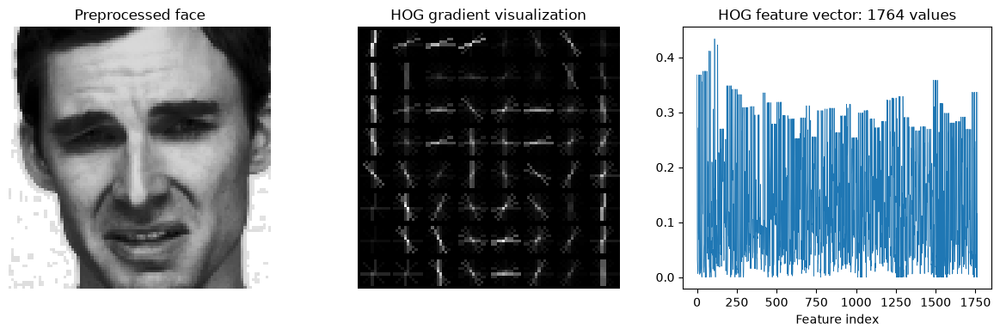

HOG feature count: 1764 = 7×7 blocks × 2×2 cells × 9 bins


In [9]:
from skimage.feature import hog, local_binary_pattern
hog_vec,hog_im=hog(still, orientations=9,pixels_per_cell=(12,12),cells_per_block=(2,2),
                   block_norm='L2-Hys',visualize=True,feature_vector=True)
fig,axs=plt.subplots(1,3,figsize=(12,4))
axs[0].imshow(still,cmap='gray');axs[0].set_title('Preprocessed face')
axs[1].imshow(hog_im,cmap='gray');axs[1].set_title('HOG gradient visualization')
axs[2].plot(hog_vec,lw=.5);axs[2].set_title(f'HOG feature vector: {len(hog_vec)} values');axs[2].set_xlabel('Feature index')
for a in axs[:2]:a.axis('off')
plt.tight_layout();plt.savefig(OUT_DIR/'03_HOG.png',dpi=150);plt.show()
print('HOG feature count:',len(hog_vec), '= 7×7 blocks × 2×2 cells × 9 bins')

## 7. LBP — Local Binary Pattern
Compare every pixel with its 8 neighbors, write a 0/1 bit per neighbor (neighbor ≥ center), convert to a binary pattern, and form a histogram. LBP emphasizes **micro-texture**; HOG emphasizes **shapes/edges**. Uniform LBP uses 10 bins for `P=8`.

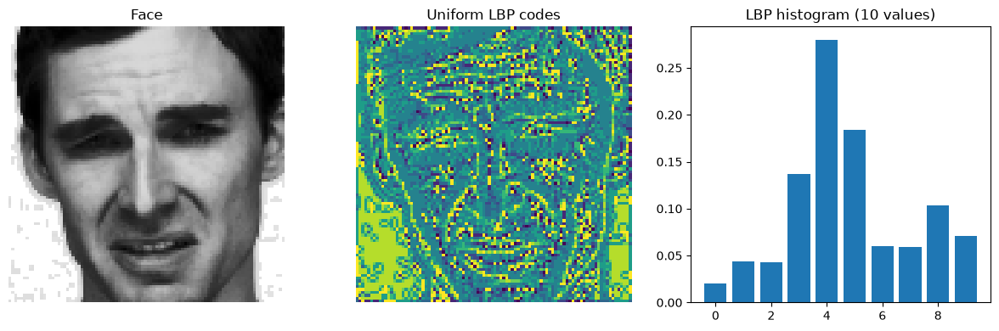

Face vector = HOG+LBP: 1774


In [10]:
lbp=local_binary_pattern(still,P=8,R=1,method='uniform')
lbp_hist=core._lbp_hist(still)
fig,axs=plt.subplots(1,3,figsize=(12,4))
axs[0].imshow(still,cmap='gray');axs[0].set_title('Face')
axs[1].imshow(lbp,cmap='viridis');axs[1].set_title('Uniform LBP codes')
axs[2].bar(range(len(lbp_hist)),lbp_hist);axs[2].set_title(f'LBP histogram ({len(lbp_hist)} values)')
for a in axs[:2]:a.axis('off')
plt.tight_layout();plt.savefig(OUT_DIR/'04_LBP.png',dpi=150);plt.show()
print('Face vector = HOG+LBP:',len(core.extract_face(still,already_cropped=True)))

## 8. MFCC — Mel-Frequency Cepstral Coefficients
Audio → split into short frames + Hamming window → FFT/power spectrum → Mel filter bank → logarithm → **DCT** → first 13 cepstral coefficients. MFCC describes **spectral envelope / timbre**, helpful for identifying a voice. We additionally compute **Delta** (rate of change) and **Delta-Delta** (change of change).

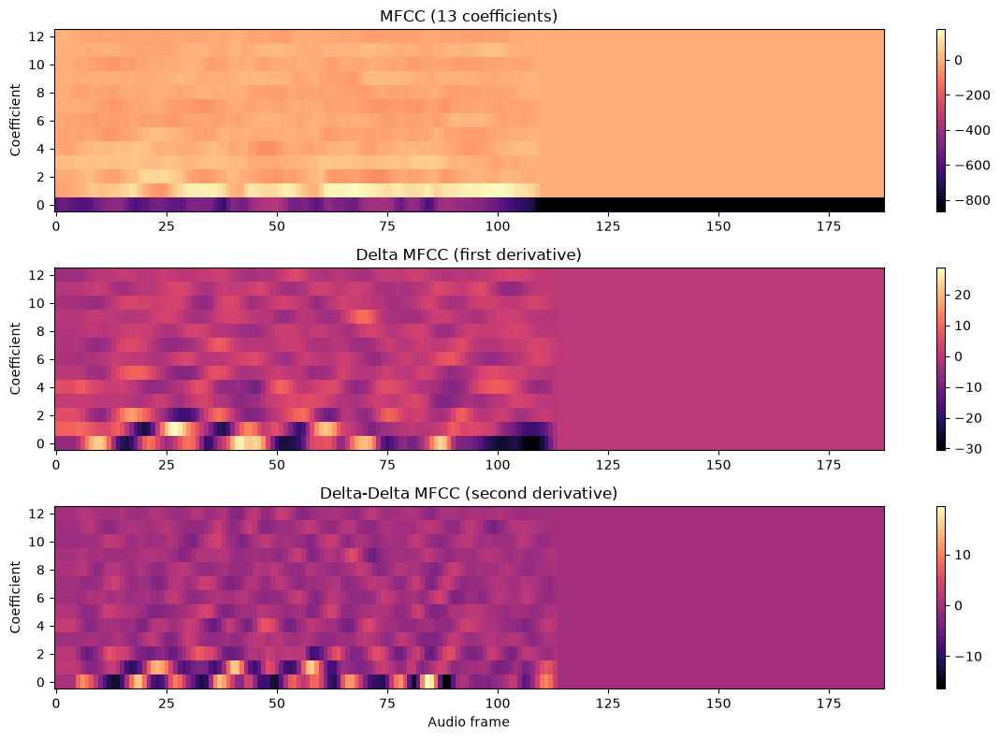

In [11]:
y,_=librosa.effects.trim(y,top_db=30)
y=librosa.util.fix_length(y,size=3*sr)
M=librosa.feature.mfcc(y=y,sr=sr,n_mfcc=13,n_fft=1024,hop_length=256)
D=librosa.feature.delta(M);DD=librosa.feature.delta(M,order=2)
fig,axs=plt.subplots(3,1,figsize=(12,8))
for a,arr,title in zip(axs,[M,D,DD],['MFCC (13 coefficients)','Delta MFCC (first derivative)','Delta-Delta MFCC (second derivative)']):
    im=a.imshow(arr,origin='lower',aspect='auto',cmap='magma');a.set_title(title);a.set_ylabel('Coefficient');plt.colorbar(im,ax=a)
axs[-1].set_xlabel('Audio frame');plt.tight_layout();plt.savefig(OUT_DIR/'05_MFCC_delta.png',dpi=150);plt.show()

## 9. Zero-Crossing Rate (ZCR) and RMS Energy
**ZCR:** the number or proportion of adjacent samples crossing positive/negative zero, per frame; reflects high-frequency/noisy vs smooth signals. **RMS:** root-mean-square amplitude, a measure of signal energy / loudness, **not** the voice identity by itself. `13 MFCC × (mean,std) + 13 Delta ×2 +13 Delta2 ×2 + ZCR×2 + RMS×2 = 82` values.

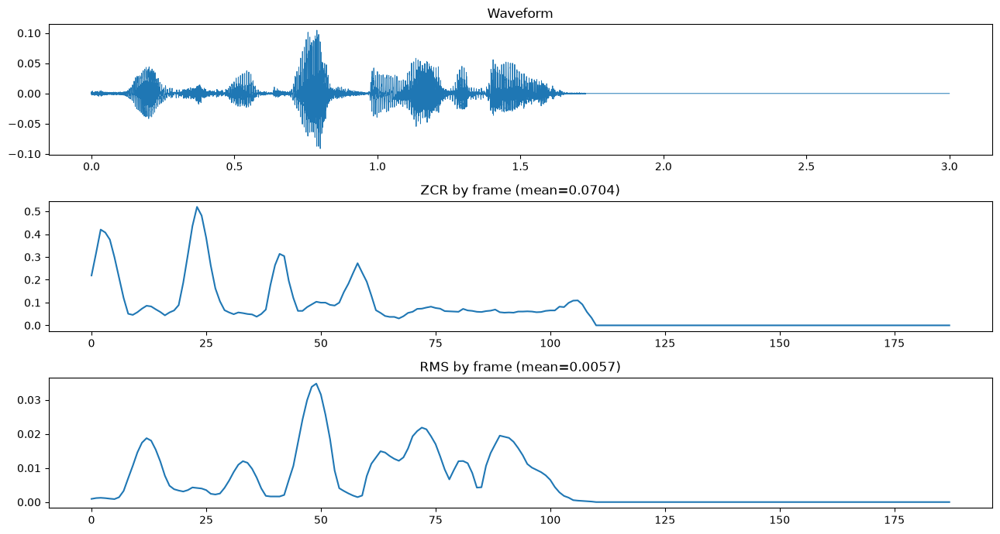

Voice vector length: 82


In [12]:
zcr=librosa.feature.zero_crossing_rate(y,frame_length=1024,hop_length=256)[0]
rms=librosa.feature.rms(y=y,frame_length=1024,hop_length=256)[0]
fig,axs=plt.subplots(3,1,figsize=(13,7))
axs[0].plot(np.arange(len(y))/sr,y,lw=.7);axs[0].set_title('Waveform')
axs[1].plot(zcr);axs[1].set_title(f'ZCR by frame (mean={zcr.mean():.4f})')
axs[2].plot(rms);axs[2].set_title(f'RMS by frame (mean={rms.mean():.4f})')
plt.tight_layout();plt.savefig(OUT_DIR/'06_ZCR_RMS.png',dpi=150);plt.show()
voice_vec=core.extract_voice(example.voice)
assert len(voice_vec)==82
print('Voice vector length:',len(voice_vec))

## 10. VIDEO feature extraction — temporal faces, no neural networks
For 6 sampled face frames, compute the same HOG+LBP per frame, then take **mean and std** across frames. This captures variation of visible facial structure/appearance across the clip. It does NOT capture full motion dynamics, optical flow, or real liveness. An attacker showing a replay may still pass; do not claim robust anti-spoofing.

Frame features shape: (6, 1774)  Video mean+std: (3548,)


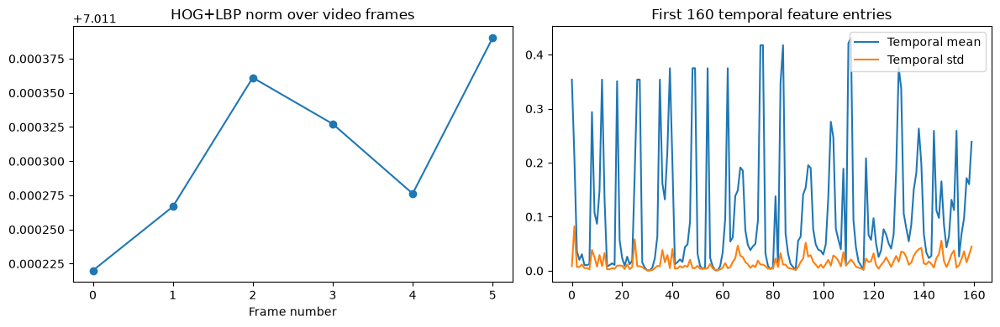

In [13]:
frame_feats=np.stack([core.extract_face(frame,already_cropped=True) for frame in vf])
video_vec=research.video_vector(example.video)
print('Frame features shape:',frame_feats.shape,' Video mean+std:',video_vec.shape)
assert len(video_vec)==2*len(core.extract_face(still,already_cropped=True))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(np.linalg.norm(frame_feats,axis=1),'o-');axs[0].set_title('HOG+LBP norm over video frames');axs[0].set_xlabel('Frame number')
axs[1].plot(video_vec[:len(video_vec)//2][:160],label='Temporal mean')
axs[1].plot(video_vec[len(video_vec)//2:][:160],label='Temporal std');axs[1].legend();axs[1].set_title('First 160 temporal feature entries')
plt.tight_layout();plt.savefig(OUT_DIR/'07_video_features.png',dpi=150);plt.show()

## 11. Compute all features (cache) + audit shapes and finite values
First run may be slow; future runs reuse `public_data/feature_cache.joblib` unless you change the manifest/extraction version. Images and video use **different face frames from the same source clip**, thus the split unit must be the **source clip/group**, not individual image frames.

In [14]:
features=research.compute_features(manifest)
feature_lengths={m:len(features.iloc[0][m+'_vec']) for m in ('image','voice','video')}
display(pd.DataFrame.from_dict(feature_lengths,orient='index',columns=['Feature vector length']))
for m,dim in feature_lengths.items():
    vectors=np.stack(features[m+'_vec'].values)
    assert vectors.shape==(len(features),dim)
    assert np.isfinite(vectors).all(),f'{m}: NaN/Inf features'
    print(m,'matrix:',vectors.shape)

image: 20/191
image: 40/191
image: 60/191
image: 80/191
image: 100/191
image: 120/191
image: 140/191
image: 160/191
image: 180/191
voice: 20/191
voice: 40/191
voice: 60/191
voice: 80/191
voice: 100/191
voice: 120/191
voice: 140/191
voice: 160/191
voice: 180/191
video: 20/191
video: 40/191
video: 60/191
video: 80/191
video: 100/191
video: 120/191
video: 140/191
video: 160/191
video: 180/191


,Feature vector length
image,1774
voice,82
video,3548


image matrix: (191, 1774)
voice matrix: (191, 82)
video matrix: (191, 3548)


## 12. How VERIFICATION differs from IDENTIFICATION
**Verification 1:1:** compare a sample to a *claimed* identity template → Same / Different. **Identification 1:N (game):** automatically compare image with all enrolled templates, propose a candidate, then verify that **same candidate** using voice. Reject unknown if score fails threshold. **Avoid teaching the model Unknown as a normal actor class.**

We first build templates using enroll split only; then create **genuine (1)** and **impostor (0)** comparison pairs from the other splits. Identity templates from train/val/test are prohibited. In the research protocol, known actor templates are separate from their own test clips; unknown actor 07 has no template at all.

In [15]:
templates=research.build_templates(features)
train_trials=research.make_trials(features,templates,'train')
val_trials=research.make_trials(features,templates,'val')+research.make_trials(features,templates,'val_unknown')
test_trials=research.make_trials(features,templates,'test')+research.make_trials(features,templates,'test_unknown')
rows=[]
for name,trials in [('train',train_trials),('validation',val_trials),('test',test_trials)]:
    rows.append({'part':name,'comparisons':len(trials),'genuine':sum(t['label'] for t in trials),
                 'impostor':sum(1-t['label'] for t in trials)})
display(pd.DataFrame(rows))
print('Pair feature lengths by mode:')
display(pd.DataFrame([{'mode':m,'features':len(train_trials[0]['x'][m]),'modalities':'+'.join(mods)}
                      for m,mods in research.MODES.items()]))
assert len(templates)==5 and set(templates)=={f'actor_{i:02d}' for i in range(1,6)}

,part,comparisons,genuine,impostor
0,train,275,55,220
1,validation,265,25,240
2,test,265,25,240


Pair feature lengths by mode:


,mode,features,modalities
0,Image Only,1775,image
1,Voice Only,83,voice
2,Video Only,3549,video
3,Early Image+Voice,1858,image+voice
4,Early Video+Voice,3632,video+voice
5,Early Image+Video,5324,image+video
6,Early All Three,5407,image+voice+video


## 13. Traditional ML training — SVM AND Random Forest for EACH modality & fusion
**SVM:** finds a separating decision boundary; uses standardized features with a nonlinear RBF kernel. **Random Forest:** averages many decision trees; captures nonlinear rules without a mandatory scaler. Each is trained on genuinely labeled pair-trials. **NO Deep Learning.**

We select models/thresholds on **validation only**, prioritizing balanced accuracy subject to a target validation FAR; report the never-used test scores only AFTER selection. Thresholds depend on a tiny seven-actor benchmark and are NOT production security thresholds.

In [16]:
print('FULL traditional model implementation:')
print(inspect.getsource(research.make_model))
print('Threshold selection using validation only:')
print(inspect.getsource(research.pick_threshold))

FULL traditional model implementation:
def make_model(name):
    if name=='SVM':
        return Pipeline([('scale',StandardScaler()),('svm',SVC(C=2,kernel='rbf',
                                    probability=True,class_weight='balanced',random_state=SEED))])
    if name=='Random Forest':
        return RandomForestClassifier(n_estimators=130,min_samples_leaf=2,
                 class_weight='balanced',n_jobs=-1,random_state=SEED)
    raise ValueError(name)

Threshold selection using validation only:
def pick_threshold(labels, scores, far_max=.05):
    y=np.asarray(labels,dtype=int)
    p=np.asarray(scores,dtype=float)
    thresholds=np.unique(np.concatenate((p,[0,1,np.nextafter(float(p.max()),np.inf)])))
    candidates=[]
    for th in thresholds:
        pred=p>=th
        neg=(y==0); pos=(y==1)
        far=float(pred[neg].mean()) if neg.any() else 0.0
        tar=float(pred[pos].mean()) if pos.any() else 0.0
        if far <= far_max + 1e-12:
            candidates.append((tar,-far

In [17]:
start=time.perf_counter()
results=research.train_public(features,artifact='model/public_models.joblib',target_far=.05)
print(f'14 trained experiments + late + hierarchical completed in {(time.perf_counter()-start)/60:.1f} minutes')
print('Saved trained verifier: model/public_models.joblib')

c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Image Only                SVM            val threshold=0.2972


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Voice Only                Random Forest  val threshold=0.5336


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Video Only                Random Forest  val threshold=0.4606


... (6 outputs left out)

c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Early All Three           Random Forest  val threshold=0.5068


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

14 trained experiments + late + hierarchical completed in 2.4 minutes
Saved trained verifier: model/public_models.joblib


## 14. Evaluation definitions — explain these in the viva
Confusion matrix on binary verification: **TP** correct genuine accept; **TN** correct impostor reject; **FP** incorrect impostor accept (dangerous); **FN** incorrect genuine reject.

- **Accuracy** `(TP+TN)/(TP+TN+FP+FN)`; useful but can be misleading when negatives dominate.
- **Precision** `TP/(TP+FP)`; fraction of accepts that were genuine.
- **Recall / TAR** `TP/(TP+FN)`; fraction of genuine users accepted.
- **F1** harmonic mean of precision+recall.
- **FAR (False Accept Rate)** `FP/(FP+TN)`; proportion of impostor attempts incorrectly accepted; important for access-control security.
- **FRR (False Reject Rate)** `FN/(FN+TP)`; proportion of real users incorrectly rejected; usability.
- **Balanced Accuracy** average of TPR and TNR; mitigates class imbalance. **ROC-AUC** compares ranking across thresholds. **EER** is approximate FAR=FRR operating point; only descriptive on held-out data, never choose deployment threshold from test data.

In [18]:
print('Confusion matrix / verification metric implementation:')
print(inspect.getsource(research.evaluate_binary))
print('\nTRAINED MODEL COMPARISON — ALL 14 EXPERIMENTS:')
model_cols=['mode','model','validation_threshold','val_accuracy','val_FAR','val_FRR','test_accuracy','test_FAR','test_FRR','test_ROC_AUC']
display(results['models'][model_cols].round(4))

Confusion matrix / verification metric implementation:
def evaluate_binary(labels,score,threshold):
    y=np.asarray(labels,dtype=int); pred=(np.asarray(score)>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':float(accuracy_score(y,pred)),
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'precision':float(precision_score(y,pred,zero_division=0)),
            'recall_TAR':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0)),
            'FAR':fp/(fp+tn) if fp+tn else np.nan,
            'FRR':fn/(fn+tp) if fn+tp else np.nan,
            'ROC_AUC':float(roc_auc_score(y,score)) if len(set(y))==2 else np.nan,
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}


TRAINED MODEL COMPARISON — ALL 14 EXPERIMENTS:


,mode,model,validation_threshold,val_accuracy,val_FAR,val_FRR,test_accuracy,test_FAR,test_FRR,test_ROC_AUC
0,Image Only,SVM,0.2972,1.0000,0.0000,0.00,0.9849,0.0042,0.12,0.9973
1,Image Only,Random Forest,0.4577,1.0000,0.0000,0.00,0.9962,0.0000,0.04,1.0000
2,Voice Only,SVM,0.5915,0.9170,0.0333,0.56,0.8792,0.0708,0.60,0.8583
3,Voice Only,Random Forest,0.5336,0.9057,0.0500,0.52,0.9132,0.0583,0.36,0.8980
4,Video Only,SVM,0.3071,0.9962,0.0000,0.04,0.9887,0.0000,0.12,0.9803
5,Video Only,Random Forest,0.4606,1.0000,0.0000,0.00,0.9925,0.0000,0.08,1.0000
6,Early Image+Voice,SVM,0.3392,1.0000,0.0000,0.00,0.9849,0.0042,0.12,0.9973
7,Early Image+Voice,Random Forest,0.4273,1.0000,0.0000,0.00,0.9962,0.0000,0.04,0.9992
8,Early Video+Voice,SVM,0.2837,0.9962,0.0000,0.04,0.9849,0.0042,0.12,0.9827
9,Early Video+Voice,Random Forest,0.4558,1.0000,0.0000,0.00,0.9887,0.0000,0.12,1.0000


## 15. Confusion Matrices — one for each trained candidate (14 total)
Every number below comes from the real TEST comparisons (not made up). Rows: TRUE (Impostor=0, Genuine=1). Columns: PREDICTED (Reject=0, Accept=1).

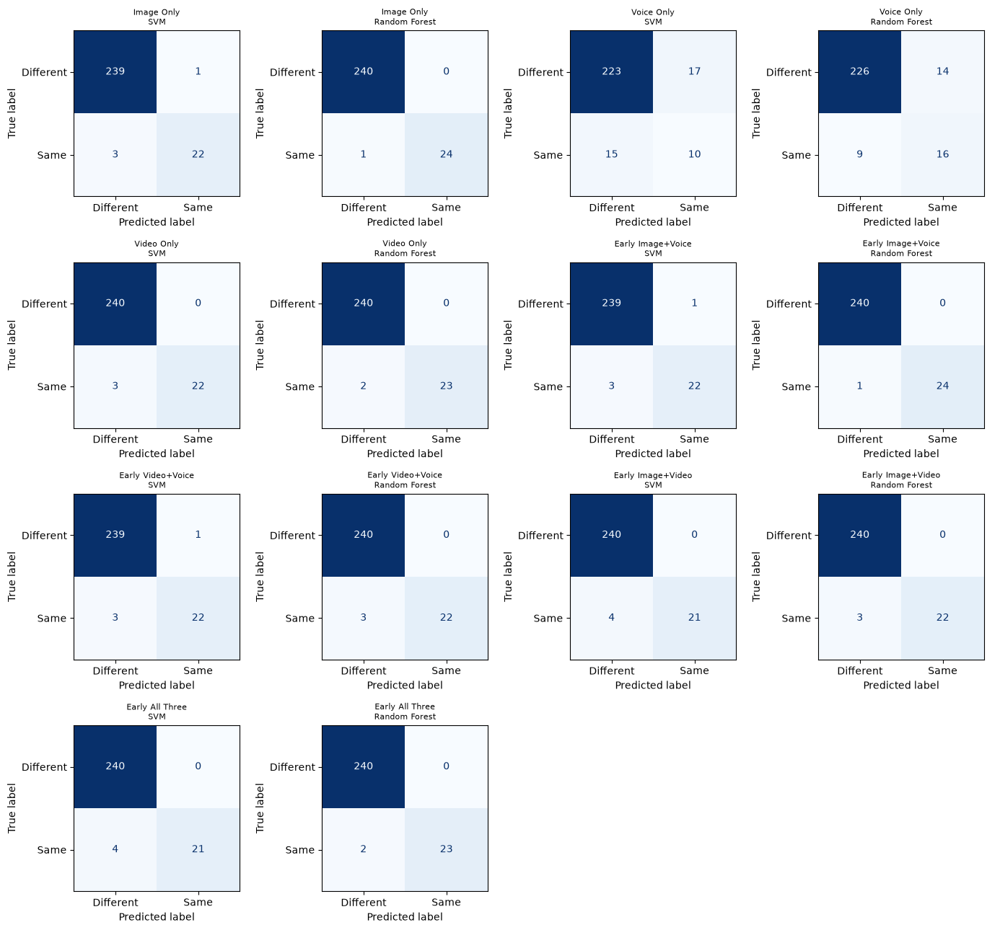

In [19]:
import matplotlib.colors as colors
from sklearn.metrics import ConfusionMatrixDisplay
trained=results['models']
fig,axes=plt.subplots(4,4,figsize=(14,13))
for ax,(_,row) in zip(axes.flat,trained.iterrows()):
    cm=np.array([[int(row.test_TN),int(row.test_FP)],[int(row.test_FN),int(row.test_TP)]])
    ConfusionMatrixDisplay(cm,display_labels=['Different','Same']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(f"{row['mode']}\n{row['model']}",fontsize=8)
for ax in list(axes.flat)[len(trained):]:ax.axis('off')
plt.tight_layout();plt.savefig(OUT_DIR/'08_all_model_confusion_matrices.png',dpi=150);plt.show()

## 16. Pick the best model per modality (validation only); compare 9 approaches
The final comparison uses one consistent test sample/claim set for image, voice, video and fusion. **Early Fusion concatenates vectors BEFORE classification**. Late Fusion combines prediction scores. Hierarchical only accepts if both independent checks pass, in sequence.

,mode,selected_model,threshold,accuracy,balanced_accuracy,precision,recall_TAR,f1,FAR,FRR,ROC_AUC
2,Video Only,Random Forest,0.4606,0.9925,0.9600,1.0000,0.92,0.9583,0.0000,0.08,1.0000
6,Early All Three,Random Forest,0.5068,0.9925,0.9600,1.0000,0.92,0.9583,0.0000,0.08,0.9992
7,Late Fusion,Decision rule,0.3624,0.9849,0.9558,0.9200,0.92,0.9200,0.0083,0.08,0.9980
5,Early Image+Video,Random Forest,0.4946,0.9887,0.9400,1.0000,0.88,0.9362,0.0000,0.12,1.0000
4,Early Video+Voice,Random Forest,0.4558,0.9887,0.9400,1.0000,0.88,0.9362,0.0000,0.12,1.0000
0,Image Only,SVM,0.2972,0.9849,0.9379,0.9565,0.88,0.9167,0.0042,0.12,0.9973
3,Early Image+Voice,SVM,0.3392,0.9849,0.9379,0.9565,0.88,0.9167,0.0042,0.12,0.9973
1,Voice Only,Random Forest,0.5336,0.9132,0.7908,0.5333,0.64,0.5818,0.0583,0.36,0.8980
8,Hierarchical,Decision rule,0.5000,0.9585,0.7800,1.0000,0.56,0.7179,0.0000,0.44,0.7800


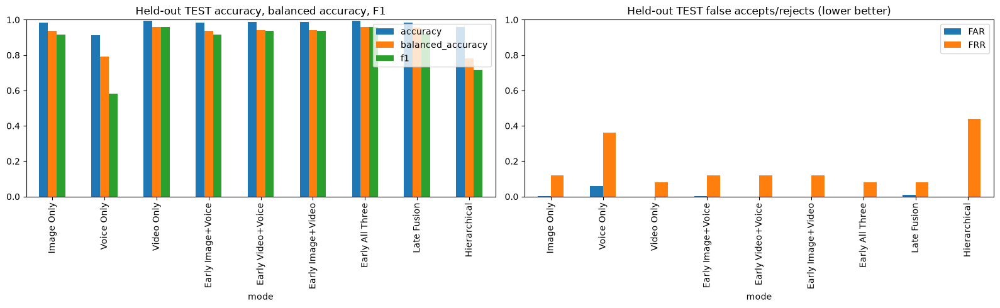

In [20]:
final=results['summary']
show=['mode','selected_model','threshold','accuracy','balanced_accuracy','precision','recall_TAR','f1','FAR','FRR','ROC_AUC']
display(final[show].sort_values('balanced_accuracy',ascending=False).round(4))
fig,axs=plt.subplots(1,2,figsize=(16,5))
final.set_index('mode')[['accuracy','balanced_accuracy','f1']].plot.bar(ax=axs[0],ylim=(0,1),title='Held-out TEST accuracy, balanced accuracy, F1')
final.set_index('mode')[['FAR','FRR']].plot.bar(ax=axs[1],ylim=(0,1),title='Held-out TEST false accepts/rejects (lower better)')
plt.tight_layout();plt.savefig(OUT_DIR/'09_model_comparison.png',dpi=150);plt.show()

## 17. Early Fusion — what exactly happens?
For **same clip & identity claim**, compute `d_image = |image - enrolled image template| + cosine`, similarly `d_voice` and `d_video`, then concatenate: `x_early = [d_image, d_voice]` (or any of 7 modality combinations). A **single SVM/RF** receives concatenated features. Each model has its own train-fitted scaler/threshold. Never concatenate unrelated speakers or differently labeled files.

In [21]:
trial=train_trials[0]
x_img=trial['x']['Image Only'];x_voice=trial['x']['Voice Only'];x_video=trial['x']['Video Only']
x_early=trial['x']['Early Image+Voice']
assert np.allclose(x_early,np.r_[x_img,x_voice])
print('Image pair vector:',x_img.shape,' Voice pair vector:',x_voice.shape)
print('Early Image+Voice shape:',x_early.shape,' = sum of lengths')
print('Early Image+Video shape:',trial['x']['Early Image+Video'].shape)
print('Early Video+Voice shape:',trial['x']['Early Video+Voice'].shape)
print('Early ALL THREE shape:',trial['x']['Early All Three'].shape)
print(inspect.getsource(research.pair_features))

Image pair vector: (1775,)  Voice pair vector: (83,)
Early Image+Voice shape: (1858,)  = sum of lengths
Early Image+Video shape: (5324,)
Early Video+Voice shape: (3632,)
Early ALL THREE shape: (5407,)
def pair_features(vecs, template, mods):
    return np.concatenate([core.pair_difference(vecs[m],template[m]) for m in mods])



## 18. Late Fusion vs Hierarchical Verification
**Late Fusion:** independent face and voice classifiers estimate scores; `0.5×face_score + 0.5×voice_score` is compared to a validation-selected threshold. **Hierarchical:** face first proposes an identity and must pass face threshold; then **voice must match that SAME person**, otherwise reject; sequential `AND`, not the same as early/late. Reject when either stage fails. Both use the same test pairs as above.

In [22]:
print('Decision logic deployed in Flask later:')
print(inspect.getsource(research.identify_from_vectors))
print('Late fusion threshold:',results['package']['late_threshold'])
for mode in ('Image Only','Voice Only','Early Image+Voice'):
    print(mode,'model=',results['package']['models'][mode]['model_name'],
          'threshold=',results['package']['models'][mode]['threshold'])

Decision logic deployed in Flask later:
def identify_from_vectors(package,vecs,mode='Hierarchical',templates=None,permissions=None):
    templates=templates if templates is not None else package['templates']
    if not templates: return {'accepted':False,'identity':'Unknown','reason':'No users enrolled'}
    if mode=='Hierarchical':
        candidate=max(templates,key=lambda u:score_claim(package,vecs,u,'Image Only',templates))
        p_face=score_claim(package,vecs,candidate,'Image Only',templates)
        p_voice=score_claim(package,vecs,candidate,'Voice Only',templates)
        allowed=(p_face>=package['models']['Image Only']['threshold'] and
                 p_voice>=package['models']['Voice Only']['threshold'])
        if permissions is not None: allowed=allowed and bool(permissions.get(candidate,False))
        return {'accepted':bool(allowed),'identity':candidate if allowed else 'Unknown',
                'reason':'Both face and voice accepted' if allowed else 'Rejected',
     

## 19. Open-Set Identification + Unknown Rejection (actual game objective)
No one selects their name. All known template IDs are searched; if scores are low, show `Unknown`. **Actor 07 is an unseen identity held out ENTIRELY until test**; actor 06 was used only to calibrate thresholds. Confusion matrix has the 5 known names + `Unknown`. Low-FAR among known claims does NOT guarantee rejecting every outsider.

,mode,known_id_accuracy,unknown_rejection_rate,unknown_false_accept_rate,overall_accuracy
0,Early All Three,0.92,1.0000,0.0000,0.9623
1,Early Image+Video,0.88,1.0000,0.0000,0.9434
2,Early Image+Voice,0.88,0.9643,0.0357,0.9245
3,Early Video+Voice,0.88,1.0000,0.0000,0.9434
4,Hierarchical,0.56,1.0000,0.0000,0.7925
5,Image Only,0.88,0.9643,0.0357,0.9245
6,Late Fusion,0.92,0.9643,0.0357,0.9434
7,Video Only,0.92,1.0000,0.0000,0.9623
8,Voice Only,0.56,0.6786,0.3214,0.6226


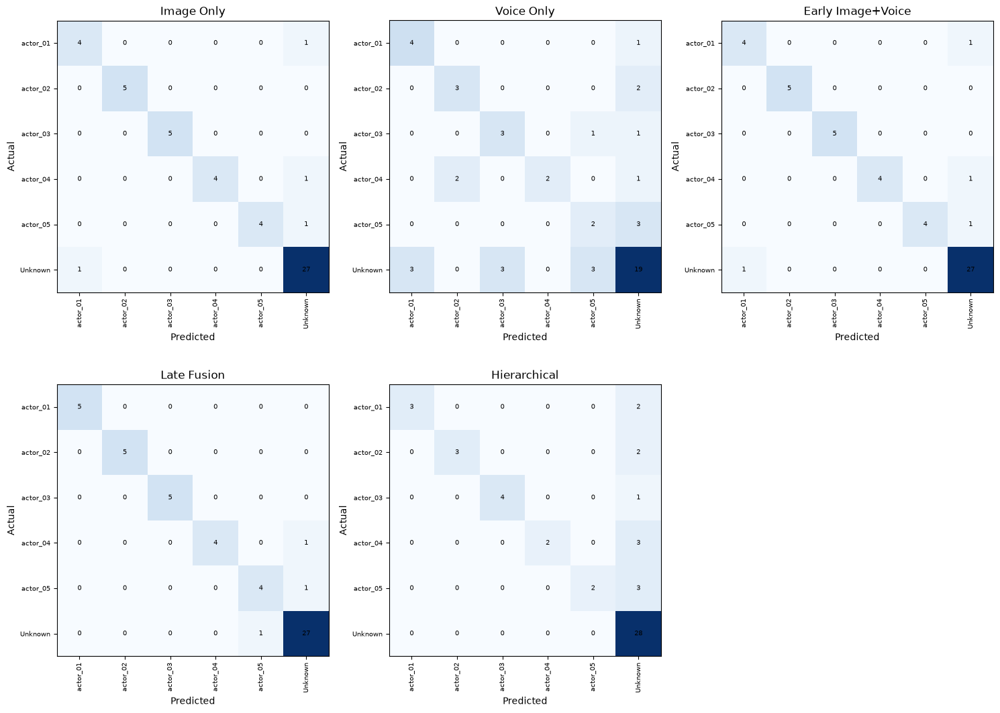

In [23]:
display(results['open_summary'].round(4))
details=results['details']
labels=sorted(templates)+['Unknown']
from sklearn.metrics import confusion_matrix
plot_modes=['Image Only','Voice Only','Early Image+Voice','Late Fusion','Hierarchical']
fig,axes=plt.subplots(2,3,figsize=(15,11))
for ax,mode in zip(axes.flat,plot_modes):
    sub=details[details['mode']==mode]
    cm=confusion_matrix(sub.actual,sub.predicted,labels=labels)
    ax.imshow(cm,cmap='Blues')
    for i in range(len(labels)):
        for j in range(len(labels)):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=7)
    ax.set_xticks(range(len(labels)),labels,rotation=90,fontsize=7)
    ax.set_yticks(range(len(labels)),labels,fontsize=7)
    ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(mode)
axes.flat[-1].axis('off');plt.tight_layout();plt.savefig(OUT_DIR/'10_open_set_confusion_matrices.png',dpi=150);plt.show()

## 20. Security scenario: matched face+voice vs stolen/mismatched voice
Take ONE known test face+audio, then substitute a DIFFERENT known actor voice. Examine both outcomes. This is a real replay/mismatch *logic* test with dataset recordings, **NOT a demonstration of presentation-attack/liveness resistance**. If an impostor gets accepted, we display that failure, never hide it.

In [24]:
known_test=features[(features.split=='test')&(features.actor<=5)]
a=known_test.iloc[0]
b=known_test[known_test.actor!=a.actor].iloc[0]
matching={'image':a.image_vec,'voice':a.voice_vec,'video':a.video_vec}
mismatching={'image':a.image_vec,'voice':b.voice_vec,'video':a.video_vec}
for desc,vecs in [('Real matching modalities',matching),('Face actor A + voice actor B',mismatching)]:
    result=research.identify_from_vectors(results['package'],vecs,mode='Hierarchical')
    print(desc,'=>',result)

Real matching modalities => {'accepted': True, 'identity': 'actor_01', 'reason': 'Both face and voice accepted', 'scores': {'face': 0.9938773286025194, 'voice': 0.6048717948717949}}
Face actor A + voice actor B => {'accepted': False, 'identity': 'Unknown', 'reason': 'Rejected', 'scores': {'face': 0.9938773286025194, 'voice': 0.11884615384615385}}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

## 21. Sensitivity: thresholds, ROC & FAR/FRR tradeoff
Threshold selection uses only Validation, not Test. A higher threshold generally lowers false accepts but increases false rejects. The observed EER estimate is an exploratory TEST statistic; it is **not** fed back to choose deployment settings.

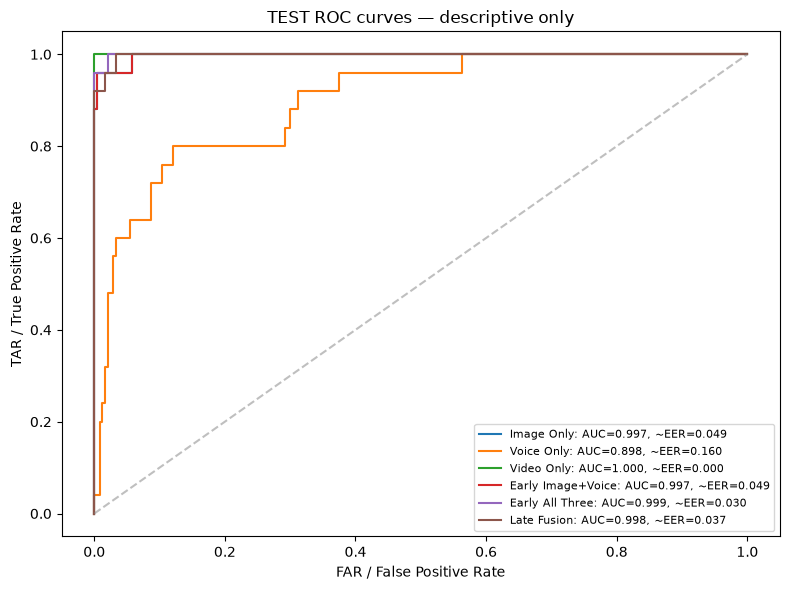

In [25]:
from sklearn.metrics import roc_curve, auc
fig,ax=plt.subplots(figsize=(8,6))
ytest=results['test_labels']
for mode in ['Image Only','Voice Only','Video Only','Early Image+Voice','Early All Three','Late Fusion']:
    scores=results['test_scores'][mode]['test']
    fpr,tpr,thresholds=roc_curve(ytest,scores)
    eer_idx=np.argmin(np.abs(fpr-(1-tpr)))
    ax.plot(fpr,tpr,label=f'{mode}: AUC={auc(fpr,tpr):.3f}, ~EER={(fpr[eer_idx]+(1-tpr[eer_idx]))/2:.3f}')
ax.plot([0,1],[0,1],'--',color='gray',alpha=.5)
ax.set(xlabel='FAR / False Positive Rate',ylabel='TAR / True Positive Rate',title='TEST ROC curves — descriptive only')
ax.legend(fontsize=8);plt.tight_layout();plt.savefig(OUT_DIR/'11_ROC_EER.png',dpi=150);plt.show()

## 22. Bonus 4 — Fingerprint (Sobel + LBP)
**RAVDESS does NOT contain fingerprints**, so DO NOT pretend to fuse unrelated fingerprints with its actors. To run real fingerprint verification, collect a CONSENTED fingerprint dataset in `fingerprint_data/<person>/<scan01>.png` etc. (at least 5 distinct scans of 3 people), or use properly licensed fingerprint data. The supplied script trains two traditional models and exports a separate fingerprint model. Real 3-modality fusion needs matching face+voice+fingerprint subjects, unavailable in RAVDESS.

In [26]:
import fingerprint_bonus
print('Sobel + LBP feature extractor source:')
print(inspect.getsource(core.extract_fingerprint))
# BONUS runs ONLY when real fingerprint scan files exist; never generates pretend results.
fingerprint_results=fingerprint_bonus.run()
if fingerprint_results is not None:
    display(fingerprint_results)
    first_scan=next(Path('fingerprint_data').glob('*/*.png'),None)
    if first_scan:
        gray=cv2.imread(str(first_scan),cv2.IMREAD_GRAYSCALE)
        gx=cv2.Sobel(gray,cv2.CV_32F,1,0);gy=cv2.Sobel(gray,cv2.CV_32F,0,1)
        fig,axes=plt.subplots(1,3,figsize=(12,4))
        for ax,v,title in zip(axes,[gray,cv2.magnitude(gx,gy),local_binary_pattern(gray,8,1,method='uniform')],
                              ['Real fingerprint','Sobel edge strength','Fingerprint LBP']):
            ax.imshow(v,cmap='gray');ax.set_title(title);ax.axis('off')
        plt.tight_layout();plt.savefig(OUT_DIR/'12_fingerprint_Sobel_LBP.png',dpi=150);plt.show()

Sobel + LBP feature extractor source:
def extract_fingerprint(image_or_path):
    """Sobel horizontal/vertical gradient orientations + uniform LBP texture."""
    image = cv2.imread(str(image_or_path)) if isinstance(image_or_path, (str, Path)) else image_or_path
    gray = cv2.resize(_gray(image), (128, 128), interpolation=cv2.INTER_AREA)
    gray = cv2.equalizeHist(gray)
    gx = cv2.Sobel(gray.astype(np.float32)/255, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray.astype(np.float32)/255, cv2.CV_32F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(gx, gy)
    orientation = (np.arctan2(gy, gx) + np.pi) % np.pi
    orientation_hist, _ = np.histogram(orientation, bins=16, range=(0, np.pi), weights=magnitude)
    orientation_hist = orientation_hist / (orientation_hist.sum() + 1e-10)
    lbp_hist = _lbp_hist(gray)
    stats = np.array([magnitude.mean(), magnitude.std(), np.percentile(magnitude, 90)])
    result = np.concatenate((orientation_hist, lbp_hist, stats)).astype(np.float32)
    as

## 23. Bonus 1 — Speech Commands after identity + permission checks
Isolated words such as `open`, `lock`, `status`, `help` use **MFCC/ZCR/RMS with SVM/RF**, not neural ASR. Speech command recognition is a separate **command** classifier; recognizing `open` is not evidence of who said it! Protect actions via server-side verified identity + permission matrix. Dataset: `commands/<word>/train/*.wav`, `val/*.wav`, `test/*.wav`. Multiple consenting speakers preferable.

In [27]:
import commands_bonus
command_results=commands_bonus.train_commands()
if command_results is not None: display(command_results)
permissions_demo={'ziad':{'open','status'},'mohamed':{'status'}}
print('Ziad verified + open:',commands_bonus.authorized_command('ziad','open',True,permissions_demo))
print('Mohamed verified + open:',commands_bonus.authorized_command('mohamed','open',True,permissions_demo))
print('Ziad unverified + open:',commands_bonus.authorized_command('ziad','open',False,permissions_demo))

BONUS PENDING: need >=2 words in commands/<word>/train|val|test/*.wav
Ziad verified + open: True
Mohamed verified + open: False
Ziad unverified + open: False


## 24. Bonus 2 — Real-time webcam + microphone verification
This machine must have camera/microphone. After you enroll a real local user, open a separate terminal and run `python live_verification.py`. Live test always uses **RAW camera frame + NEW audio recording**, not training photos. If camera detection or voice audio fails, access is denied. Webcam/mic are not automatically activated during Run All, so Notebook remains reproducible.

In [28]:
print('Local live demo: python live_verification.py')
print('Camera input -> HOG/LBP -> face candidate; microphone -> MFCC/ZCR/RMS -> verify same candidate; permissions -> decision')
import live_verification
print(inspect.getsource(live_verification.main))

Local live demo: python live_verification.py
Camera input -> HOG/LBP -> face candidate; microphone -> MFCC/ZCR/RMS -> verify same candidate; permissions -> decision
def main():
    parser=argparse.ArgumentParser()
    parser.add_argument('--seconds',type=int,default=3)
    a=parser.parse_args()
    model=deployment.load_verifier()
    gallery=deployment.load_gallery()
    if not gallery['templates']:
        print('Please enroll users first: see README / deployment.enroll_user');return
    frame=capture()
    input('Press ENTER to record your voice for 3 seconds ...')
    signal=sd.rec(a.seconds*16000,samplerate=16000,channels=1,dtype='float32')
    sd.wait()
    with tempfile.TemporaryDirectory() as root:
        image=Path(root)/'attempt.png';voice=Path(root)/'attempt.wav'
        if not cv2.imwrite(str(image),frame):raise RuntimeError('Failed to save camera capture')
        sf.write(str(voice),signal[:,0],16000)
        decision=deployment.verify_new_attempt(image,voice,package=mod

## 25. Bonus 3 — Add User at game runtime, NOT training on that user in Notebook
The trained verifier exports **fixed learned same/different decision rules**. When an admin enrolls someone with 4 new photos + 4 WAV recordings, the backend computes the **same** features, averages each modality into a new identity template, and saves it in `model/enrollment_gallery.joblib`. The gallery is distinct from the public RAVDESS research templates. No public test score is changed, and no global SVM retraining is needed. You can later opt to retrain for domain adaptation, but that must use a separate controlled validation/test set.

**Important:** 4 enrollment photos/recordings are minimum demo inputs, NOT sufficient to guarantee secure verification. Keep separate held-out attempts, test strangers and replay attacks. Identity and permissions must be administered server-side. The gallery begins EMPTY.

In [29]:
print(inspect.getsource(deployment.enroll_user))
print(inspect.getsource(deployment.verify_new_attempt))
print('Gallery initial state (no actual user registered automatically):')
print(deployment.load_gallery())
# Example after real files exist (DO NOT run now):
# deployment.enroll_user('ziad', ['photos/1.png','photos/2.png','photos/3.png','photos/4.png'],
#                        ['voices/1.wav','voices/2.wav','voices/3.wav','voices/4.wav'],allowed=True)

def enroll_user(name, image_paths, audio_paths, allowed=True, gallery_file=None, video_paths=None,
                fingerprint_paths=None):
    """Enroll with >=4 real faces and >=4 real audio recordings (4 recommended).
    Adds a new template immediately; retains the public-trained verifier.
    Audio and image need not be frame-synchronized at enrollment, as both belong to same consented user.
    """
    name=validate_new_username(name)
    if len(image_paths)<4 or len(audio_paths)<4:
        raise ValueError('At least 4 distinct face photos AND 4 voice recordings required')
    # Every new face MUST be detected in un-cropped media.
    face=np.stack([core.extract_face(Path(p),require_face=True) for p in image_paths])
    voice=np.stack([core.extract_voice(Path(p)) for p in audio_paths])
    templates={'image':face.mean(axis=0).astype('float32'),
               'voice':voice.mean(axis=0).astype('float32')}
    if video_paths:
        video=np.stack([research.video_vector(p) for p i

## 26. Export every file required by Flask
The trained verifier and validation thresholds are serialized to `model/public_models.joblib`; the backend imports **the exact same Python feature functions** from `bioguard_core.py`, `public_research.py`, and `deployment.py`. Do not retrain an arbitrary new model in Flask with a different feature order. CSV reports, diagrams, model manifest, and code helpers remain here. **Never load untrusted `.joblib` or `.pickle` uploads.**

In [30]:
assert (MODEL_DIR/'public_models.joblib').exists(), 'TRAIN first!'
manifest_models=deployment.export_summary()
display(pd.DataFrame([{'mode':k,**v} for k,v in manifest_models['models'].items()]))
print('EXPORTED FILES:')
for p in sorted(MODEL_DIR.glob('*')):
    if p.is_file():print(f' {p}   {p.stat().st_size/1024:.1f} KB')
print('\nREPORT & PLOT FILES:')
for p in sorted(OUT_DIR.glob('*')):
    if p.is_file():print(' ',p)

,mode,model,threshold,modalities
0,Image Only,SVM,0.297165,[image]
1,Voice Only,Random Forest,0.533590,[voice]
2,Video Only,Random Forest,0.460623,[video]
3,Early Image+Voice,SVM,0.339184,"[image, voice]"
4,Early Video+Voice,Random Forest,0.455769,"[video, voice]"
5,Early Image+Video,Random Forest,0.494615,"[image, video]"
6,Early All Three,Random Forest,0.506777,"[image, voice, video]"


EXPORTED FILES:
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\.gitkeep   0.0 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\model_manifest.json   1.5 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\open_set_comparison.csv   0.6 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\open_set_test_predictions.csv   27.4 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\public_mode_comparison.csv   1.4 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\public_model_comparison.csv   3.2 KB
 c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\model\public_models.joblib   6897.2 KB

REPORT & PLOT FILES:
  c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\outputs\.gitkeep
  c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE\outputs\01_dataset_exploration.png
  c:\Users\Abdelrahman Mohamed\Downloads\BioGuard_Task2_COMPLETE

## 27. Reload-and-infer smoke test (real test clip)
This proves the exported package loads, the exact feature order is reused, and a previously unseen **test clip** is evaluated. Does not imply a 100% success rate.

In [31]:
reloaded=deployment.load_verifier()
assert set(reloaded['models'])==set(research.MODES)
first_test=features[features.split=='test'].iloc[0]
vecs={m:first_test[m+'_vec'] for m in ('image','voice','video')}
print('True subject:',first_test.user)
for mode in ['Image Only','Voice Only','Video Only','Early Image+Voice','Early All Three','Late Fusion','Hierarchical']:
    pred=research.identify_from_vectors(reloaded,vecs,mode=mode)
    print(f'{mode:24s}: {pred}')

True subject: actor_01
Image Only              : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.9938773286025194, 'threshold': 0.29716524286407703}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

Voice Only              : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.6048717948717949, 'threshold': 0.5335897435897436}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

Video Only              : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.6319658119658119, 'threshold': 0.46062271062271065}
Early Image+Voice       : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.9947981970762904, 'threshold': 0.339183947435582}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

Early All Three         : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.5878205128205127, 'threshold': 0.5067765567765568}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

Late Fusion             : {'accepted': True, 'identity': 'actor_01', 'reason': 'Accepted', 'score': 0.7993745617371572, 'threshold': 0.36236467271408984}
Hierarchical            : {'accepted': True, 'identity': 'actor_01', 'reason': 'Both face and voice accepted', 'scores': {'face': 0.9938773286025194, 'voice': 0.604871794871795}}


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to pr

## 28. What to explain in oral examination (English / Arabic quick answers)
| Question | Short explanation |
|---|---|
| What is HOG? | Gradient edge directions and magnitudes in local cells; shape/structure. |
| What is LBP? | Binary comparisons with neighboring pixels; local texture. |
| Why HOG + LBP? | Complementary shape and texture; concatenate their histograms. |
| MFCC? | Mel-scale spectral envelope: framing → FFT → Mel filters → log → DCT; 13 cepstral coefficients. |
| Delta / Delta-Delta? | First and second temporal change of MFCC. |
| ZCR? | Rate of zero-sign crossings; high for noisy/high-frequency content. |
| RMS? | Square root of mean squared amplitude, representing signal energy. |
| Audio coefficients? | 13 MFCC × mean/std; plus delta, delta², ZCR and RMS, total 82. |
| Video vs still? | Video pools HOG/LBP across multiple frames (mean/std); face observations are correlated. |
| Two ML models? | SVM with scaler + Random Forest for every modality and fusion. |
| Verification vs identification? | Is the claimed person real? vs who is this? Door uses candidate search then strict same-person verification. |
| Early vs Late fusion? | Before classification concatenate features vs after classification combine scores. |
| Hierarchical? | Stage 1 face candidate/pass then Stage 2 voice same-person/pass then permission. |
| FAR / FRR? | Impostor accepted / genuine rejected; tradeoff important for security and usability. |
| Why subject-disjoint unknown split? | To test rejection of an actor absent from training/gallery, preventing open-set leakage. |
| Did RAVDESS contain fingerprint? | No. Separate genuine fingerprint data required; no cross-person fusion claims. |
| Did employee data retrain the SVM? | No, classic transferable pairwise verifier stays fixed; templates updated locally at enrollment. |

**Prepare for:** A particular 7-actor dataset result is not a guarantee of real-life performance. RAVDESS has clean studio recordings; replay/liveness spoofing remains an unsolved limitation in this educational demo. A different language/room/device can cause domain shift.

## 29. Check delivered artifacts + Codex game prompt
Send `CODEX_FLASK_GAME_PROMPT.md` to Codex with this complete folder. Codex must implement a local Flask game with **Add User** (4 photos/4 audio uploads or live capture), Admin auth, Gallery, Camera+Mic entry, stages, animations, permissions, and **Unknown** rejection, using `model/public_models.joblib`. Run training notebook BEFORE asking Codex to load saved models.

In [32]:
necessary=[Path('model/public_models.joblib'),Path('model/model_manifest.json'),
           Path('model/public_model_comparison.csv'),Path('model/public_mode_comparison.csv'),
           Path('model/open_set_comparison.csv'),Path('outputs/09_model_comparison.png')]
for p in necessary:
    print('OK' if p.exists() else 'MISSING',p)
assert all(p.exists() for p in necessary)
print('Research notebook COMPLETE — game can now consume model/ and Python helper modules.')

OK model\public_models.joblib
OK model\model_manifest.json
OK model\public_model_comparison.csv
OK model\public_mode_comparison.csv
OK model\open_set_comparison.csv
OK outputs\09_model_comparison.png
Research notebook COMPLETE — game can now consume model/ and Python helper modules.


# DYNAMIC ENROLLMENT & LOCAL BIOMETRIC MATCHING

This deployment research section extends the preserved public research results. It evaluates the versioned local gallery matcher used by Flask and imports the same implementation from `bioguard_matching.py`. The public RAVDESS SVM, Random Forest comparisons, notebooks, model artifacts, and their reported outputs remain unchanged.

The experiment uses the existing feature cache and its explicit `enroll`, `val`, `test`, `val_unknown`, and `test_unknown` partitions. Validation samples are used for method/threshold selection; the held-out test partitions are reported only after selection. When local private media are unavailable, that limitation is recorded rather than inferred around.

## Research design and decision rule

**Feature extraction.** Face samples use the original HOG + LBP extractor and voice samples use the original MFCC + ZCR + RMS extractor from `bioguard_core.py`. No deep learning is introduced. Flask enrollment stores individual vectors, not only an average, so a live sample is compared with the enrolled gallery.

**Candidate matchers.** The shared module evaluates cosine similarity, standardized cosine similarity, standardized Euclidean distance, and nearest-neighbor / KNN-template aggregation. The original public pair SVM remains an academic benchmark; it is not silently treated as a calibrated new-user gallery matcher.

For vectors $x$ and $y$, cosine similarity is

$$\operatorname{cos}(x,y)=\frac{x\cdot y}{\|x\|_2\|y\|_2}.$$

For standardized features $z=(x-\mu)/(\sigma+\epsilon)$, the distance matcher uses

$$d_z(x,y)=\|z_x-z_y\|_2,$$

and converts it to a higher-is-better score only for common threshold handling. KNN methods aggregate the strongest $k$ individual template scores. Standardization statistics are computed from the research enrollment partition and are versioned with the local matching configuration.

**Hierarchical deployment rule.** Face identification and unknown rejection happen first. Voice is then verified only against that same face candidate. The door decision is `face_match AND voice_match AND door_permission`; command mode independently requires speaker verification, command confidence, and the action permission.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

import bioguard_matching as shared_matching
from flask_game.tools.benchmark_local_matching import (
    load_public_features,
    _public_gallery,
    _claim_trials,
    _test_claim_confusion,
    benchmark_modality,
)

deployment_frame = load_public_features()
all_rows = []
chosen_rows = {}
score_distributions = {}
for modality in ("image", "voice"):
    rows, chosen = benchmark_modality(deployment_frame, modality)
    all_rows.extend(rows)
    chosen_rows[modality] = chosen
    gallery = _public_gallery(deployment_frame, modality)
    genuine, impostor = _claim_trials(
        deployment_frame, gallery, modality, chosen["method"], "val", "val_unknown"
    )
    score_distributions[modality] = {"genuine": genuine, "impostor": impostor}

comparison_table = pd.DataFrame(all_rows)[[
    "modality", "method", "threshold", "validation_far", "validation_frr",
    "validation_known_id_rate", "validation_unknown_rejection_rate",
    "test_known_id_rate", "test_unknown_rejection_rate", "test_unknown_far",
]]
display(comparison_table.round(4))

selected_table = pd.DataFrame([
    {"modality": modality, **row} for modality, row in chosen_rows.items()
])[[
    "modality", "method", "threshold", "validation_far", "validation_frr",
    "validation_tar", "validation_known_id_rate", "validation_unknown_rejection_rate",
    "test_known_id_rate", "test_unknown_rejection_rate", "test_unknown_far",
    "claim_TN", "claim_FP", "claim_FN", "claim_TP",
]]
display(selected_table.round(4))

metric_rows = []
for modality, row in chosen_rows.items():
    cm = _test_claim_confusion(
        deployment_frame, _public_gallery(deployment_frame, modality),
        modality, row["method"], row["threshold"]
    )
    tn, fp, fn, tp = (cm[key] for key in ("TN", "FP", "FN", "TP"))
    precision, recall, f1, _ = precision_recall_fscore_support(
        [0] * (tn + fp) + [1] * (fn + tp),
        [0] * tn + [1] * fp + [0] * fn + [1] * tp,
        average="binary", zero_division=0,
    )
    metric_rows.append({
        "modality": modality,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix_TN_FP_FN_TP": (tn, fp, fn, tp),
    })
display(pd.DataFrame(metric_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, modality in zip(axes, ("image", "voice")):
    dist = score_distributions[modality]
    axis.hist(dist["genuine"], bins=12, alpha=0.65, label="genuine validation")
    axis.hist(dist["impostor"], bins=12, alpha=0.65, label="impostor / unknown validation")
    axis.axvline(chosen_rows[modality]["threshold"], color="black", linestyle="--", label="selected threshold")
    axis.set_title(f"{modality.title()} score distributions")
    axis.set_xlabel("higher-is-better score")
    axis.set_ylabel("count")
    axis.legend()
plt.tight_layout()
plt.show()

print("Actors/splits are inherited from the existing manifest; validation is used for calibration and test is held out.")
print("The public SVM comparison is preserved in model/public_mode_comparison.csv and is not overwritten by this gallery experiment.")

## Calibration, export, and Flask integration

Thresholds are calibrated from validation genuine/impostor scores at the predeclared target validation FAR (`0.05`) and are not tuned on the final test partition. FAR/FRR are measurable only for the available research partitions. A single local employee gallery cannot establish a trustworthy unknown-person FAR; additional independent users are required.

The benchmark writes the versioned configuration to `flask_game/local_matching_calibration.json`. Flask calls `bioguard_matching.calibration_for(...)` and `hierarchical_verify(...)`; it does not maintain a second threshold table. The notebook and Flask therefore share extraction, normalization, scoring, calibration metadata, and the fail-closed face → voice → permission decision. The existing public SVM threshold remains available for comparison diagnostics only.
The exact current voice deployment selection is `cosine_nn` on individual MFCC/ZCR/RMS templates with threshold `0.999384722048567`, target validation FAR `0.05`, validation claim FAR `0.05`, validation FRR `0.52`, validation known-ID rate `0.48`, and validation unknown-rejection rate `0.642857`. It is a provisional public-reference calibration, not a local-user accuracy claim.

In [ ]:
from pathlib import Path
import json
import bioguard_matching as shared_matching
from flask_game import inference as flask_inference

config_path = Path("flask_game/local_matching_calibration.json")
if config_path.exists():
    exported = json.loads(config_path.read_text(encoding="utf-8"))
    print(json.dumps({
        "version": exported.get("version"),
        "target_validation_far": exported.get("target_validation_far"),
        "modalities": {
            key: {"method": value.get("method"), "threshold": value.get("threshold"), "source": value.get("source")}
            for key, value in exported.get("modalities", {}).items()
        },
    }, indent=2))
else:
    print("Calibration export is created by flask_game/tools/benchmark_local_matching.py")

assert flask_inference.extract_face_live is shared_matching.extract_face_live
assert flask_inference.extract_voice is shared_matching.extract_voice
assert flask_inference.hierarchical_verify is shared_matching.hierarchical_verify
print("Flask and notebook import the same shared biometric functions.")

In [ ]:
public_modes = pd.read_csv("model/public_mode_comparison.csv")
public_view = public_modes[public_modes["mode"].isin(["Image Only", "Voice Only", "Hierarchical"])][["mode", "selected_model", "threshold", "FAR", "FRR", "F1", "ROC_AUC"]]
display(public_view.round(4))
print("The table above is the preserved public research comparison; the local gallery rows above are a separate deployment experiment.")